# 5.24

1. Calculate the initial slope $x'(0)$:
\begin{align*}
x'(0) &= -0.5 \cdot x(0)\\
x'(0) &= -0.5 \times 6\\
x'(0) &= -3\\
\end{align*}


2. Estimate the value of $x$ at the midpoint $t = 0.5$ using the initial slope:
\begin{align*}
x(0.5) &\approx x(0) + \frac{dt}{2} \cdot x'(0)\\
x(0.5) &\approx 6 + \frac{1}{2} \times (-3)\\
x(0.5) &\approx 6 - 1.5 \\
x(0.5) &\approx 4.5 \\
\end{align*}


3. Find the slope at the midpoint $t = 0.5$ using the estimated value of $x(0.5)$:
\begin{align*}
x'(0.5) &= -0.5 \cdot x(0.5)\\
x'(0.5) &= -0.5 \times 4.5\\
x'(0.5) &= -2.25\\
\end{align*}


4. Use the slope at the midpoint to estimate $x$ at $t = 1$:
\begin{align*}
x(1) &\approx x(0) + dt \cdot x'(0.5) \\
x(1) &\approx 6 + 1 \times (-2.25) \\
x(1) &\approx 6 - 2.25 \\
 x(1) &\approx 3.75 \\
\end{align*}

In [1]:
import numpy as np


def f(t, x):
    return -0.5 * x


def exact_solution(t):
    return 6 * np.exp(-0.5 * t)


def midpoint_method(f, x0, t0, tmax, dt):
    """Second-order Runge-Kutta (midpoint) method."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for i in range(len(t) - 1):
        x_mid = x[i] + 0.5 * dt * f(t[i], x[i])
        x[i + 1] = x[i] + dt * f(t[i] + 0.5 * dt, x_mid)
    return t, x


t_vals, x_midpoint = midpoint_method(f, 6, 0, 10, 1)
x_exact_vals = exact_solution(t_vals)
print(f"midpoint: {x_midpoint}")
print(f"exact:    {x_exact_vals}")


midpoint: [6.         3.75       2.34375    1.46484375 0.91552734 0.57220459
 0.35762787 0.22351742 0.13969839 0.08731149 0.05456968]
exact:    [6.         3.63918396 2.20727665 1.33878096 0.8120117  0.49250999
 0.29872241 0.1811843  0.10989383 0.06665398 0.04042768]


### Outcome comes from Euler's method
Approximations of x(t): 
$$[6, 3.0, 1.5, 0.75, 0.375, 0.1875, 0.09375, 0.046875, 0.0234375, 0.01171875, 0.005859375]$$


Exact values of x(t): 
$$[6, 3.6391839582758005, 2.207276647028654, 1.338780960890579, 0.8120116994196762, 0.4925099917433928, 0.29872241020718365, 0.181184300533911, 0.10989383333240507, 0.06665397922945383, 0.0404276819945128]$$

# 5.32

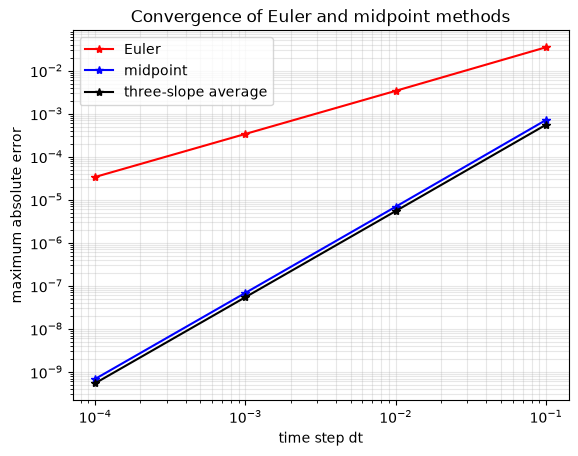

In [2]:
import matplotlib.pyplot as plt


def euler(f, x0, t0, tmax, dt):
    """Explicit Euler method."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        x[n + 1] = x[n] + dt * f(t[n], x[n])
    return t, x


def ode_test(f, x0, t0, tmax, dt):
    """Three-slope average method from the exercise."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        k1 = f(t[n], x[n])
        k2 = f(t[n] + dt / 2, x[n] + dt * k1 / 2)
        k3 = f(t[n] + dt, x[n] + dt * k2)
        x[n + 1] = x[n] + dt * (k1 + k2 + k3) / 3
    return t, x


f = lambda t, x: -(1 / 3.0) * x + np.sin(t)
exact = lambda t: (1 / 10.0) * (19 * np.exp(-t / 3) + 3 * np.sin(t) - 9 * np.cos(t))

x0, t0, tmax = 1, 0, 3
# dt = 1e-5 and 1e-6 add cost without adding information to the slope.
H = 10.0 ** (-np.arange(1, 5))
errors = {"euler": [], "midpoint": [], "test": []}

for dt in H:
    t, x_euler = euler(f, x0, t0, tmax, dt)
    t, x_midpoint = midpoint_method(f, x0, t0, tmax, dt)
    t, x_test = ode_test(f, x0, t0, tmax, dt)
    reference = exact(t)
    errors["euler"].append(np.max(np.abs(x_euler - reference)))
    errors["midpoint"].append(np.max(np.abs(x_midpoint - reference)))
    errors["test"].append(np.max(np.abs(x_test - reference)))

plt.loglog(H, errors["euler"], "r*-", label="Euler")
plt.loglog(H, errors["midpoint"], "b*-", label="midpoint")
plt.loglog(H, errors["test"], "k*-", label="three-slope average")
plt.xlabel("time step dt")
plt.ylabel("maximum absolute error")
plt.title("Convergence of Euler and midpoint methods")
plt.grid(which="both", alpha=0.3)
plt.legend()
plt.show()
